In [58]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [59]:
# load in data
df = pd.read_csv('master_county_quarter.csv')
df

,county_fips,year,quarter,county_name,quarter_end_date,zhvi_usd,zori_usd_month,fhfa_hpi,hpi_index_basis,hpi_source_frequency,...,state_any_preliminary,state_unemployment_rate_pct,state_partial_quarter,state_missing_reason,price_to_income,price_to_rent,zhvi_usd_t_plus_12,zori_usd_month_t_plus_12,zhvi_growth_3y_pct,zori_growth_3y_pct
0,39017,2015,1,Butler,2015-03-31,149168.737654,911.716903,108.43,2000=100,annual,...,False,5.156904,False,NaN,2.537531,13.634417,176361.703414,988.610991,18.229668,8.433987
1,39017,2015,2,Butler,2015-06-30,150342.535126,913.214387,108.43,2000=100,annual,...,False,5.003161,False,NaN,2.557498,13.719171,179308.169485,999.902153,19.266427,9.492597
2,39017,2015,3,Butler,2015-09-30,151982.493042,921.860654,108.43,2000=100,annual,...,False,4.791291,False,NaN,2.585396,13.738744,181854.497276,1007.308707,19.654898,9.269086
3,39017,2015,4,Butler,2015-12-31,154402.017868,931.253594,108.43,2000=100,annual,...,False,4.856418,False,NaN,2.626555,13.816682,183574.431559,1017.243987,18.893803,9.233832
4,39017,2016,1,Butler,2016-03-31,157291.559970,929.009159,112.34,2000=100,annual,...,False,4.998171,False,NaN,2.485919,14.109258,188297.054374,1029.501950,19.712116,10.817201
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
391,39165,2024,4,Warren,2024-12-31,396233.049134,1843.619670,218.92,2000=100,annual,...,False,4.684356,False,NaN,3.539312,17.910104,NaN,NaN,NaN,NaN
392,39165,2025,1,Warren,2025-03-31,400462.734993,1866.230530,227.71,2000=100,annual,...,False,4.844308,False,NaN,NaN,17.881979,NaN,NaN,NaN,NaN
393,39165,2025,2,Warren,2025-06-30,401408.845172,1883.558665,227.71,2000=100,annual,...,False,4.675468,False,NaN,NaN,17.759329,NaN,NaN,NaN,NaN
394,39165,2025,3,Warren,2025-09-30,403261.842796,1902.931156,227.71,2000=100,annual,...,False,4.407797,False,NaN,NaN,17.659679,NaN,NaN,NaN,NaN


In [ ]:
# to explore distributions and trends of labor, demographic, and macroeconomic predictors, identify all variables
labor_feat = ["cty_employed", "cty_labor_force", 'cty_unemployed', 'cty_unemployment_rate_pct']
macro_feat = [ 'state_unemployed','state_unemployment_rate_pct','state_employed', 'state_labor_force']
demo_feat = ["housing_units", 'median_household_income_usd', 'occupancy_total_units', 'population', 'vacancy_rate_pct', 'vacant_housing_units']

year = [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

# Check correlation with ZHVI/ZORI growth
labor_zz_feat = ["cty_employed", "cty_labor_force", 'cty_unemployed', 'cty_unemployment_rate_pct','zhvi_growth_3y_pct', 'zhvi_usd', 'zhvi_usd_t_plus_12', 'zori_growth_3y_pct', 'zori_usd_month', 'zori_usd_month_t_plus_12']
macro_zz_feat = [ 'state_unemployed','state_unemployment_rate_pct','state_employed', 'state_labor_force', 'zhvi_growth_3y_pct', 'zhvi_usd', 'zhvi_usd_t_plus_12', 'zori_growth_3y_pct', 'zori_usd_month', 'zori_usd_month_t_plus_12']
demo_zz_feat = ["housing_units", 'median_household_income_usd', 'occupancy_total_units', 'population', 'vacancy_rate_pct', 'vacant_housing_units', 'zhvi_growth_3y_pct', 'zhvi_usd', 'zhvi_usd_t_plus_12', 'zori_growth_3y_pct', 'zori_usd_month', 'zori_usd_month_t_plus_12']


2015 Q1
                           cty_employed  cty_labor_force  cty_unemployed  \
cty_employed                   1.000000         0.999898        0.962106   
cty_labor_force                0.999898         1.000000        0.965909   
cty_unemployed                 0.962106         0.965909        1.000000   
cty_unemployment_rate_pct     -0.186002        -0.173914        0.051078   
zhvi_growth_3y_pct             0.832729         0.828854        0.728934   
zhvi_usd                      -0.225173        -0.232616       -0.358943   
zhvi_usd_t_plus_12            -0.133621        -0.141749       -0.283738   
zori_growth_3y_pct             0.536427         0.528207        0.360473   
zori_usd_month                -0.064857        -0.070600       -0.171991   
zori_usd_month_t_plus_12       0.016217         0.009398       -0.114335   

                           cty_unemployment_rate_pct  zhvi_growth_3y_pct  \
cty_employed                               -0.186002            0.832729   
ct

In [78]:

for (year, quarter), df_quarter in df.groupby(["year", "quarter"]):
    corr = df_quarter[labor_zz_feat].corr()
    print(f"\n{year} Q{quarter}")
    print(corr)


2015 Q1
                           cty_employed  cty_labor_force  cty_unemployed  \
cty_employed                   1.000000         0.999898        0.962106   
cty_labor_force                0.999898         1.000000        0.965909   
cty_unemployed                 0.962106         0.965909        1.000000   
cty_unemployment_rate_pct     -0.186002        -0.173914        0.051078   
zhvi_growth_3y_pct             0.832729         0.828854        0.728934   
zhvi_usd                      -0.225173        -0.232616       -0.358943   
zhvi_usd_t_plus_12            -0.133621        -0.141749       -0.283738   
zori_growth_3y_pct             0.536427         0.528207        0.360473   
zori_usd_month                -0.064857        -0.070600       -0.171991   
zori_usd_month_t_plus_12       0.016217         0.009398       -0.114335   

                           cty_unemployment_rate_pct  zhvi_growth_3y_pct  \
cty_employed                               -0.186002            0.832729   
ct

In [79]:
for (year, quarter), df_quarter in df.groupby(["year", "quarter"]):
    corr = df_quarter[macro_zz_feat].corr()
    print(f"\n{year} Q{quarter}")
    print(corr)


2015 Q1
                             state_unemployed  state_unemployment_rate_pct  \
state_unemployed                          NaN                          NaN   
state_unemployment_rate_pct               NaN                          NaN   
state_employed                            NaN                          NaN   
state_labor_force                         NaN                          NaN   
zhvi_growth_3y_pct                        NaN                          NaN   
zhvi_usd                                  NaN                          NaN   
zhvi_usd_t_plus_12                        NaN                          NaN   
zori_growth_3y_pct                        NaN                          NaN   
zori_usd_month                            NaN                          NaN   
zori_usd_month_t_plus_12                  NaN                          NaN   

                             state_employed  state_labor_force  \
state_unemployed                        NaN                NaN   


In [80]:
for (year, quarter), df_quarter in df.groupby(["year", "quarter"]):
    corr = df_quarter[demo_zz_feat].corr()
    print(f"\n{year} Q{quarter}")
    print(corr)


2015 Q1
                             housing_units  median_household_income_usd  \
housing_units                     1.000000                    -0.435123   
median_household_income_usd      -0.435123                     1.000000   
occupancy_total_units             1.000000                    -0.435123   
population                        0.994031                    -0.389850   
vacancy_rate_pct                  0.513348                    -0.843095   
vacant_housing_units              0.955870                    -0.503951   
zhvi_growth_3y_pct                0.777026                    -0.298243   
zhvi_usd                         -0.313259                     0.972429   
zhvi_usd_t_plus_12               -0.231358                     0.955979   
zori_growth_3y_pct                0.475600                    -0.059356   
zori_usd_month                   -0.128730                     0.915168   
zori_usd_month_t_plus_12         -0.055854                     0.883065   

               

## labor variable EDA

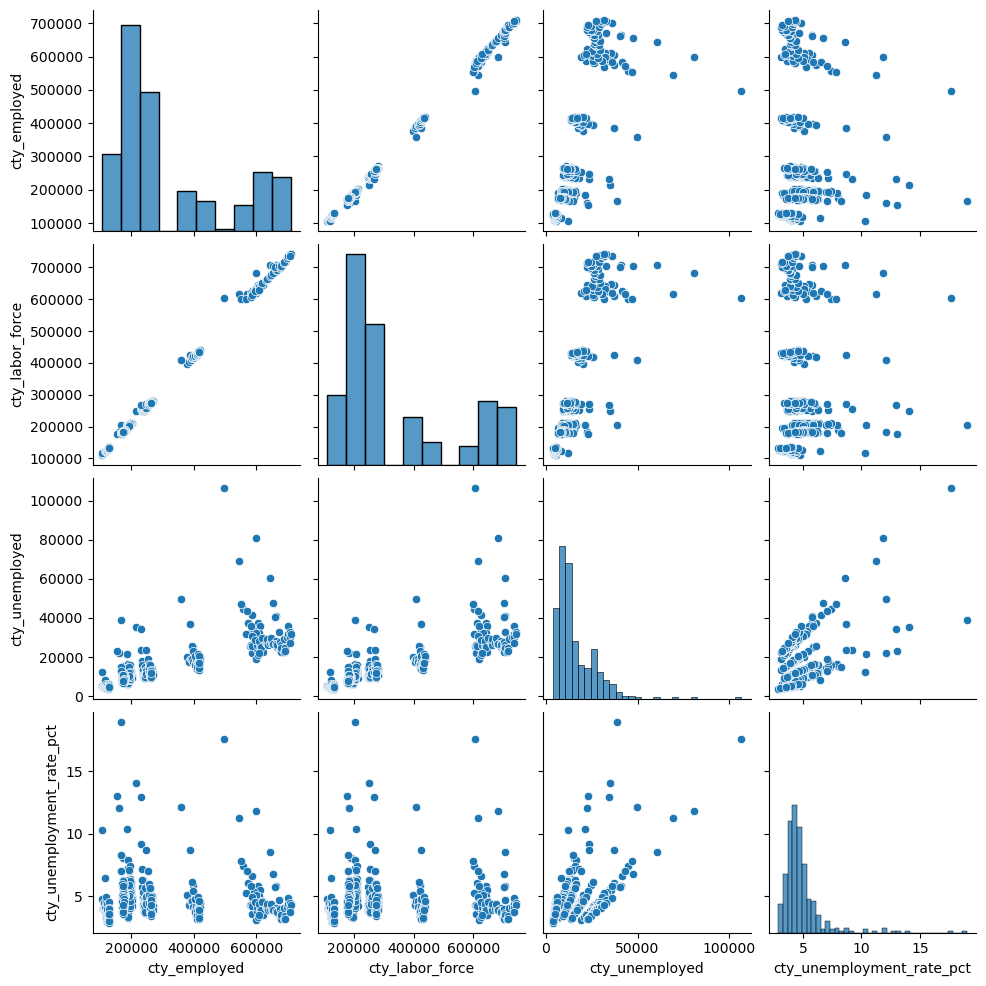

In [61]:
# labor variables pair plot
sns.pairplot(df[labor_feat[:5]])

# labor variables correlation
corr = df[labor_feat].corr()

In [62]:
for year in years:
    df_year = df[df["year"] == year]
    corr = df_year[labor_feat].corr()
    print(f"\nCorrelation Matrix for {year}")
    print(corr)


Correlation Matrix for 2015
                           cty_employed  cty_labor_force  cty_unemployed  \
cty_employed                   1.000000         0.999903        0.954271   
cty_labor_force                0.999903         1.000000        0.958351   
cty_unemployed                 0.954271         0.958351        1.000000   
cty_unemployment_rate_pct     -0.159231        -0.147356        0.102045   

                           cty_unemployment_rate_pct  
cty_employed                               -0.159231  
cty_labor_force                            -0.147356  
cty_unemployed                              0.102045  
cty_unemployment_rate_pct                   1.000000  

Correlation Matrix for 2016
                           cty_employed  cty_labor_force  cty_unemployed  \
cty_employed                   1.000000         0.999921        0.964727   
cty_labor_force                0.999921         1.000000        0.967952   
cty_unemployed                 0.964727         0.967952  

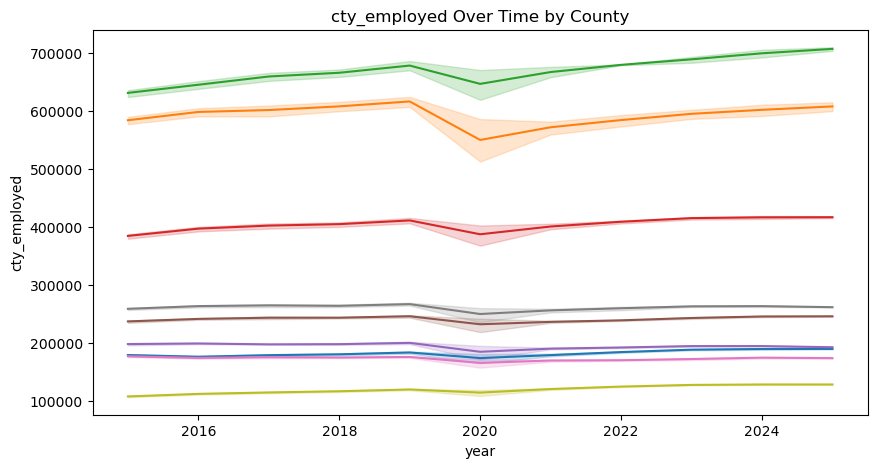

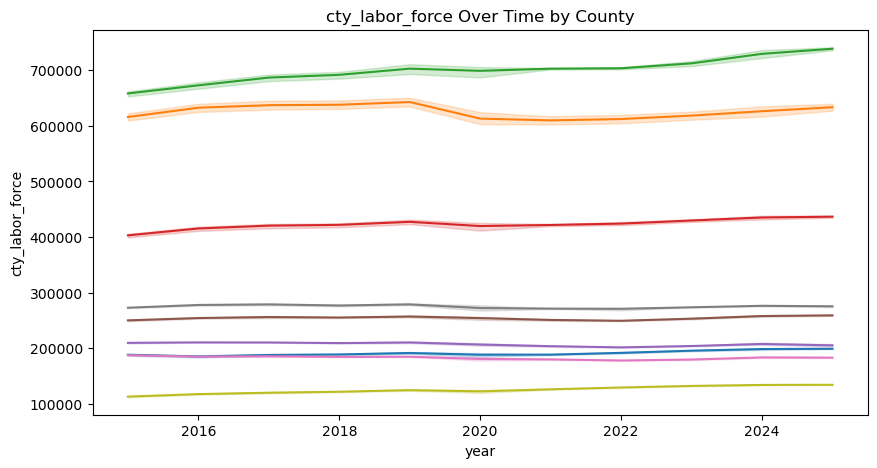

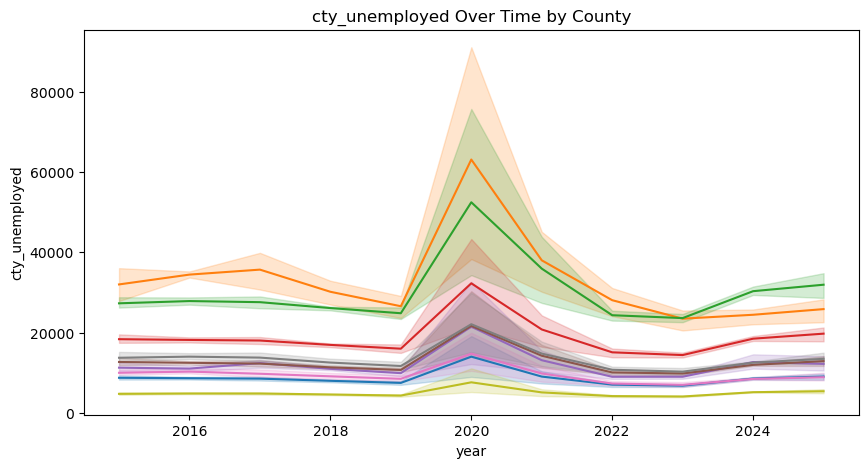

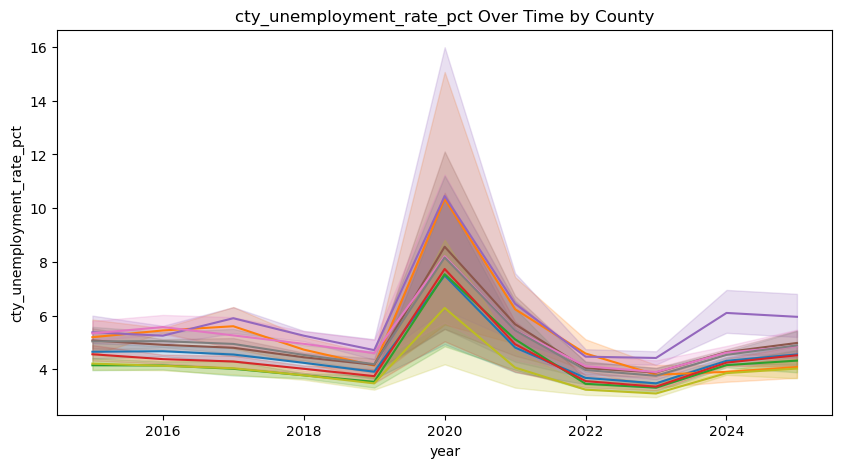

In [64]:
for feature in labor_feat:
    plt.figure(figsize=(10, 5))
    sns.lineplot(data=df, x="year", y=feature, hue="county_name", legend=False)
    plt.title(f"{feature} Over Time by County")
    plt.show()

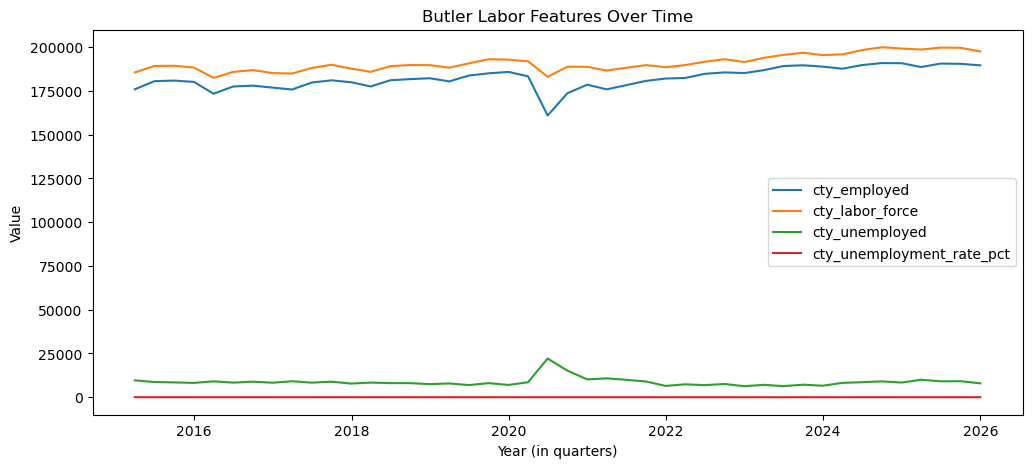

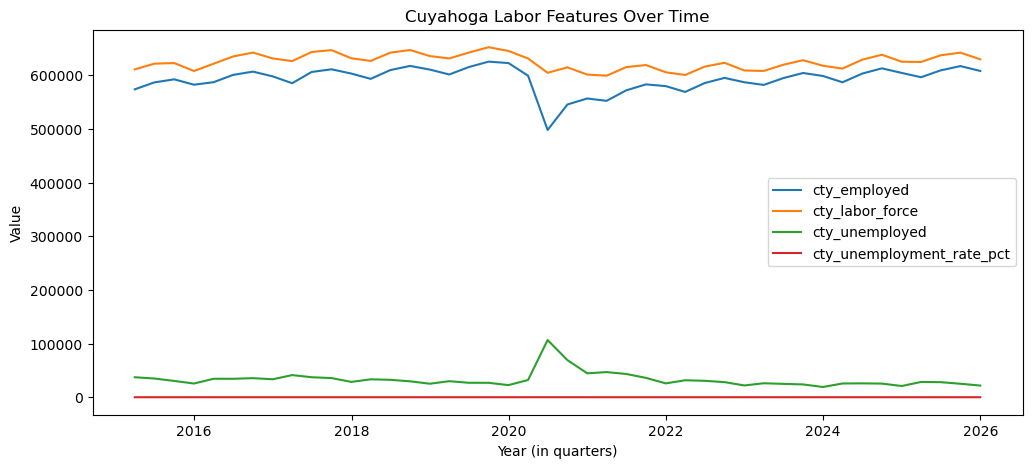

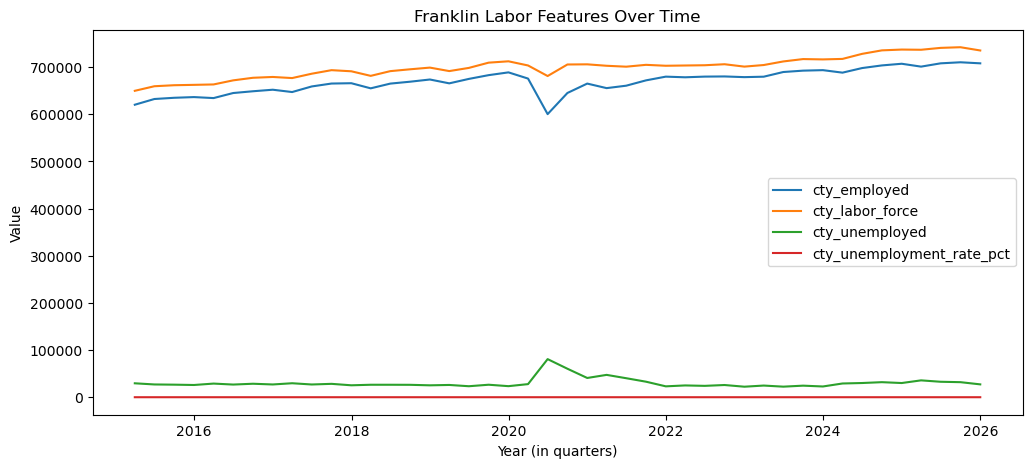

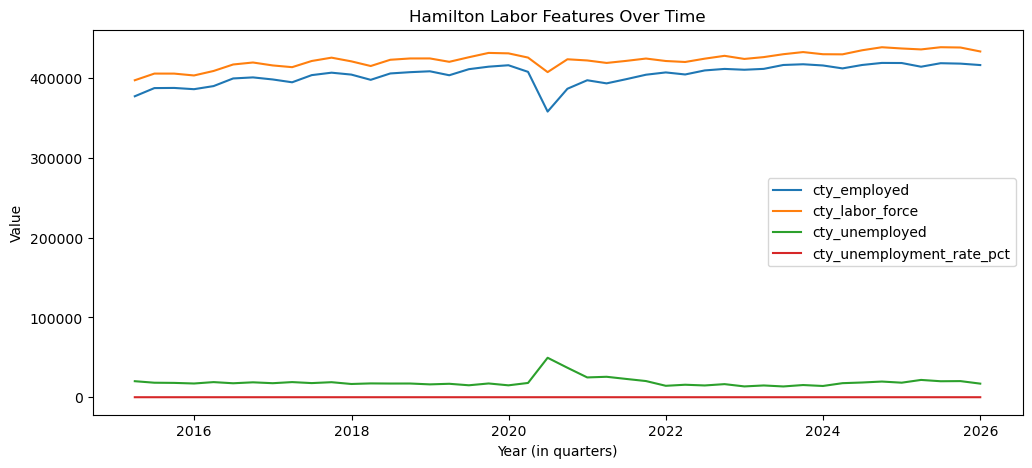

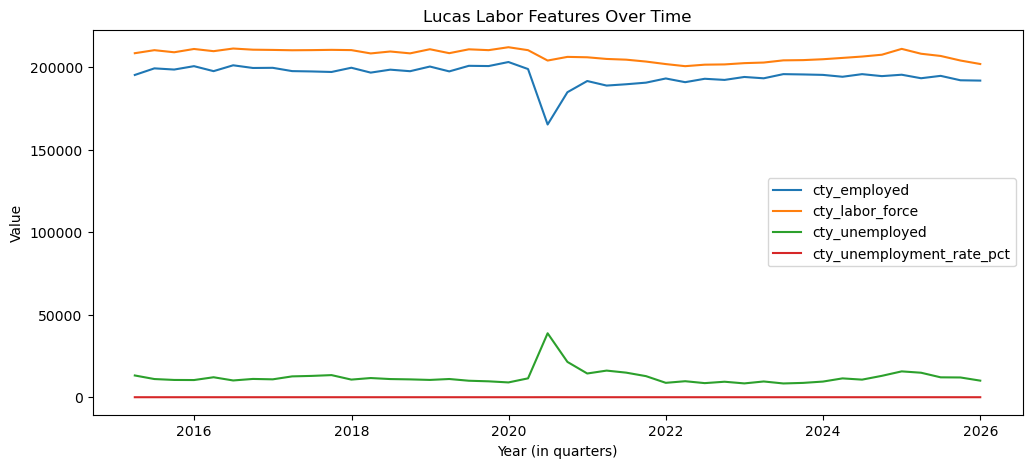

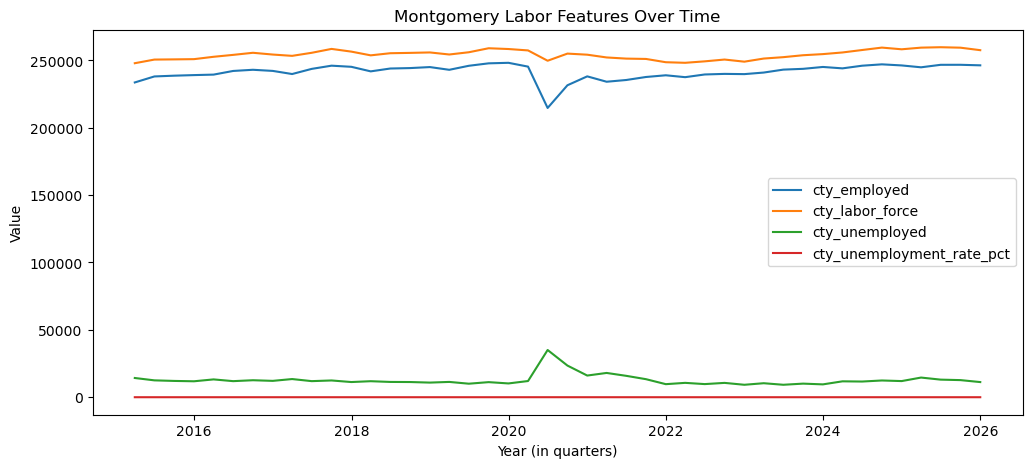

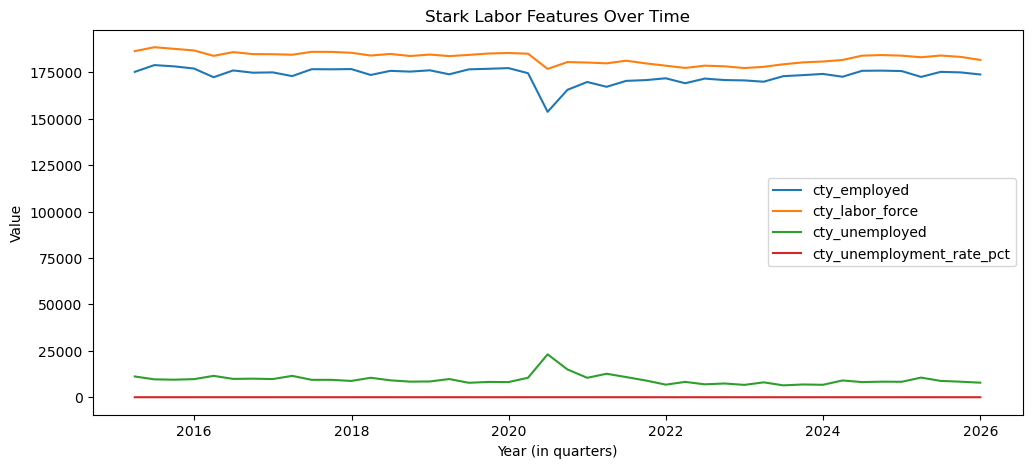

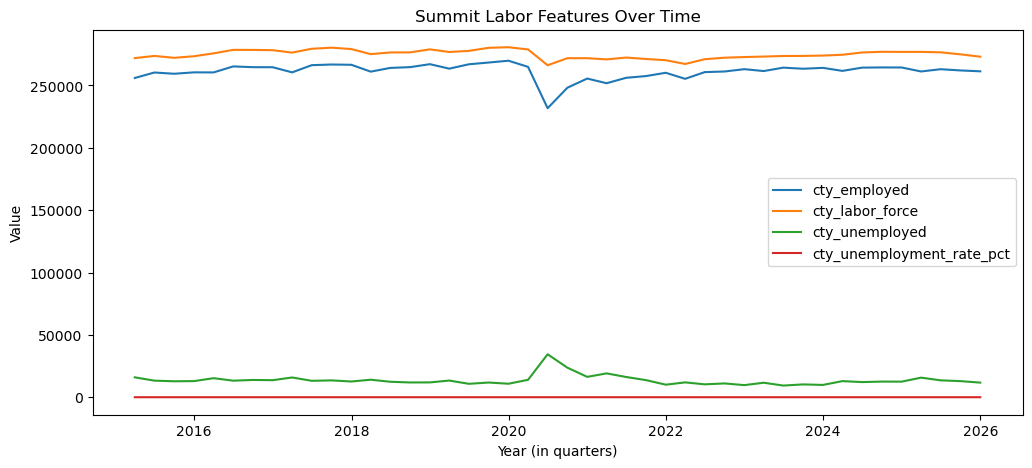

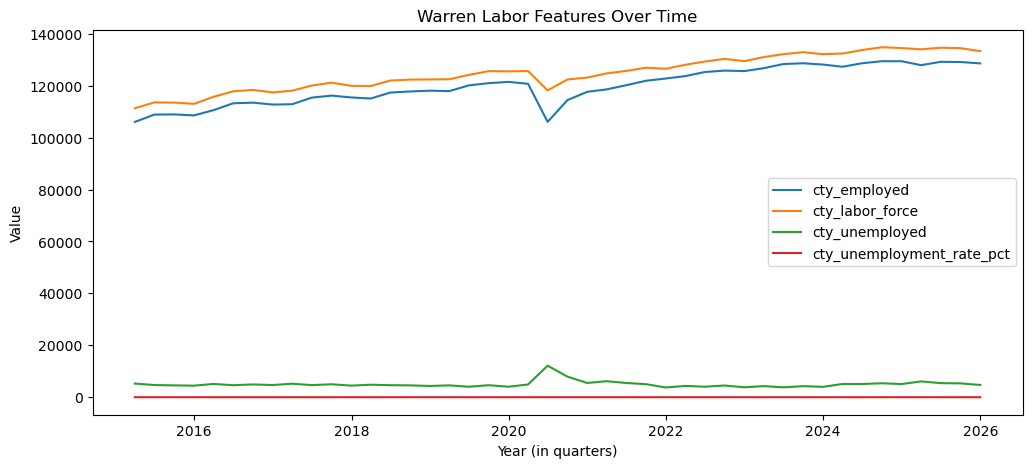

In [71]:
df["quarter_end_date"] = pd.to_datetime(df["quarter_end_date"])

for county in df["county_name"].unique():
    df_county = df[df["county_name"] == county].sort_values("quarter_end_date")

    plt.figure(figsize=(12, 5))

    for feature in labor_feat:
        sns.lineplot(data=df_county, x="quarter_end_date", y=feature, label=feature)

    plt.title(f"{county} Labor Features Over Time")
    plt.xlabel("Year (in quarters)")
    plt.ylabel("Value")
    plt.legend()
    plt.show()

# macro variable (state-level)

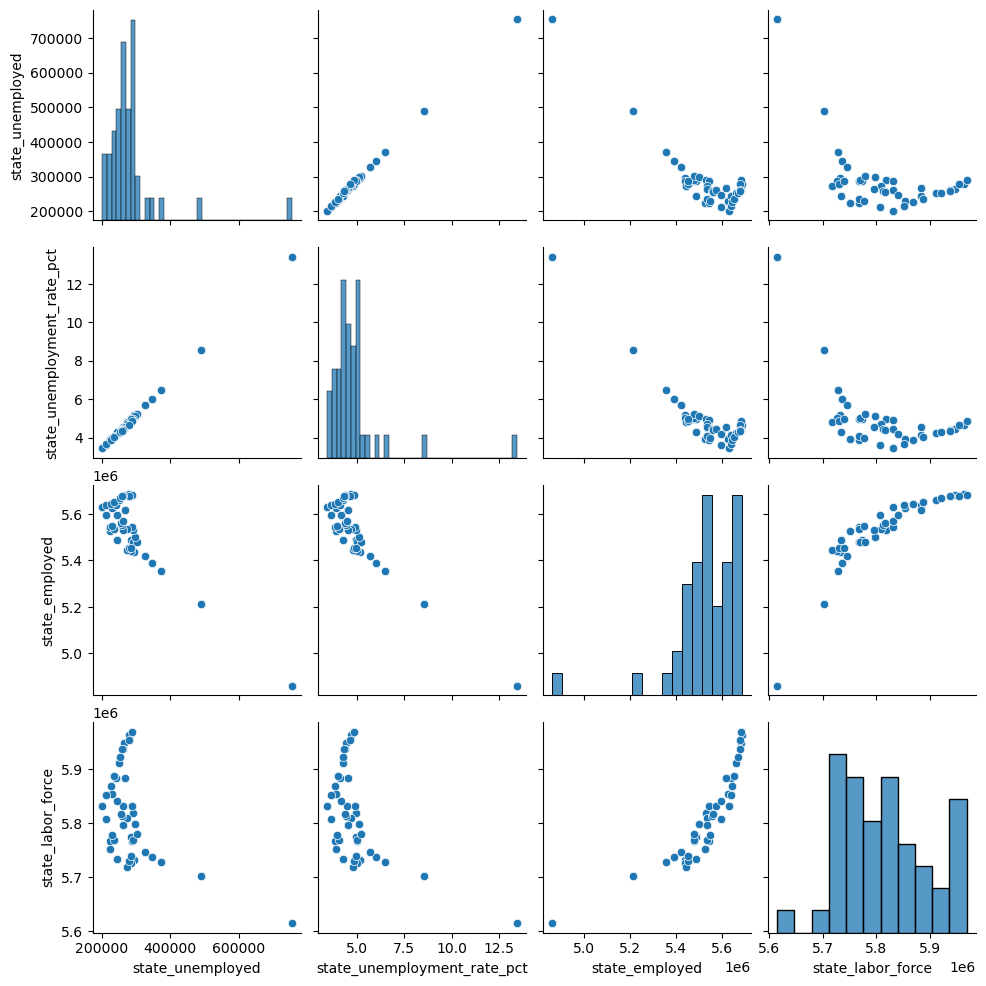

In [48]:
# labor variables pair plot
sns.pairplot(df[macro_feat[:5]])

# labor variables correlation
corr = df[macro_feat].corr()

In [49]:
for year in years:
    df_year = df[df["year"] == year]
    corr = df_year[macro_feat].corr()
    print(f"\nCorrelation Matrix for {year}")
    print(corr)


Correlation Matrix for 2015
                             state_unemployed  state_unemployment_rate_pct  \
state_unemployed                     1.000000                     0.999724   
state_unemployment_rate_pct          0.999724                     1.000000   
state_employed                      -0.731055                    -0.746879   
state_labor_force                    0.716773                     0.700197   

                             state_employed  state_labor_force  
state_unemployed                  -0.731055           0.716773  
state_unemployment_rate_pct       -0.746879           0.700197  
state_employed                     1.000000          -0.048216  
state_labor_force                 -0.048216           1.000000  

Correlation Matrix for 2016
                             state_unemployed  state_unemployment_rate_pct  \
state_unemployed                     1.000000                     0.999658   
state_unemployment_rate_pct          0.999658                     1.00

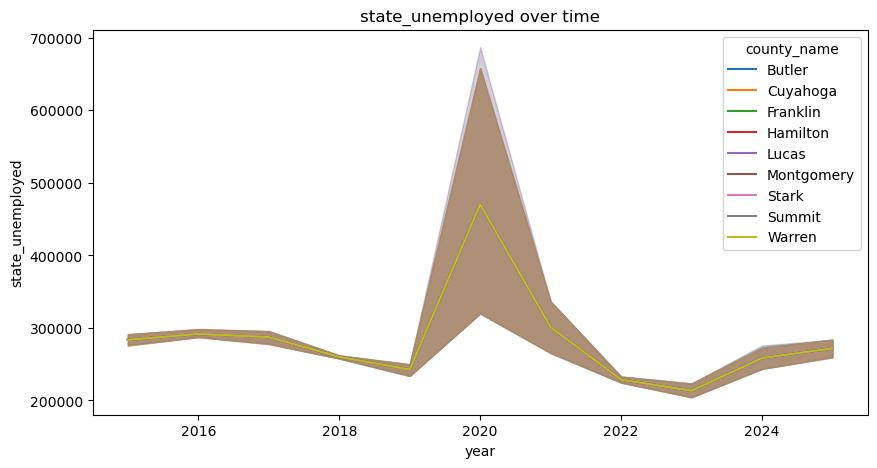

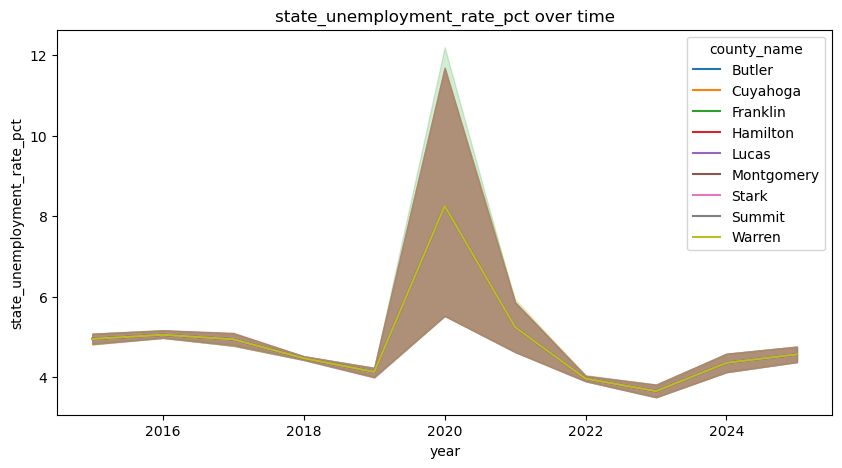

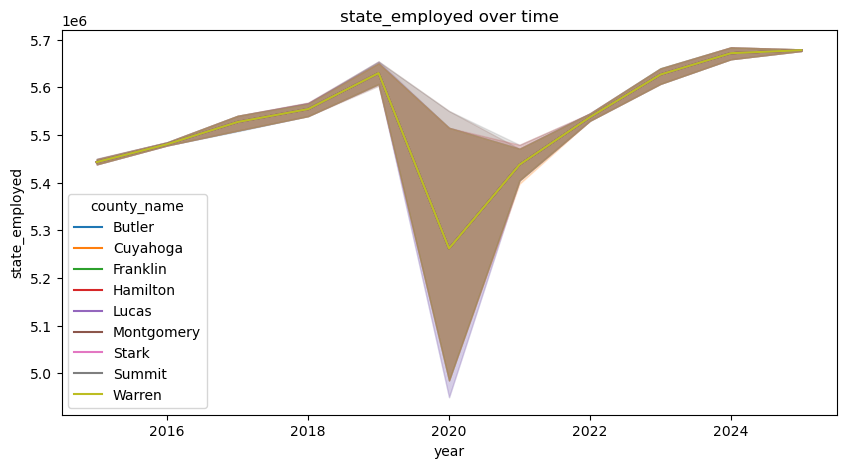

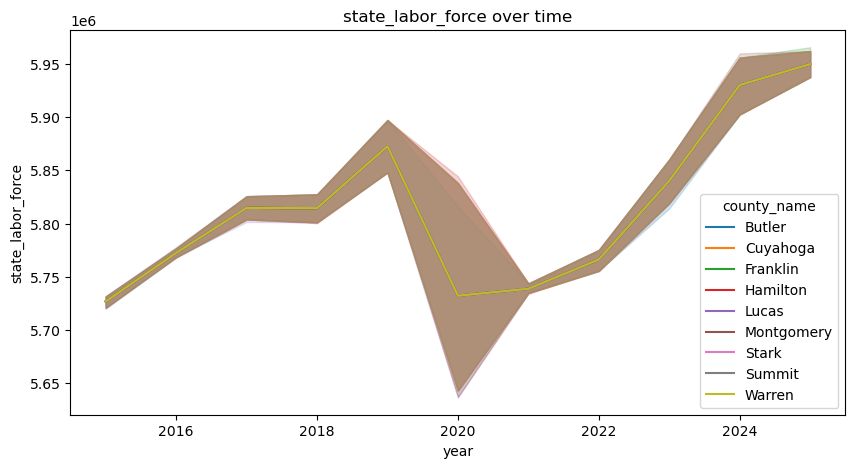

In [ ]:
# One figure per labor feature
for feature in macro_feat:
    plt.figure(figsize=(10, 5))
    sns.lineplot(data=df, x="year", y=feature, hue="county_name", legend=True)
    plt.title(f"{feature} over time")
    plt.show()

# demographic variables

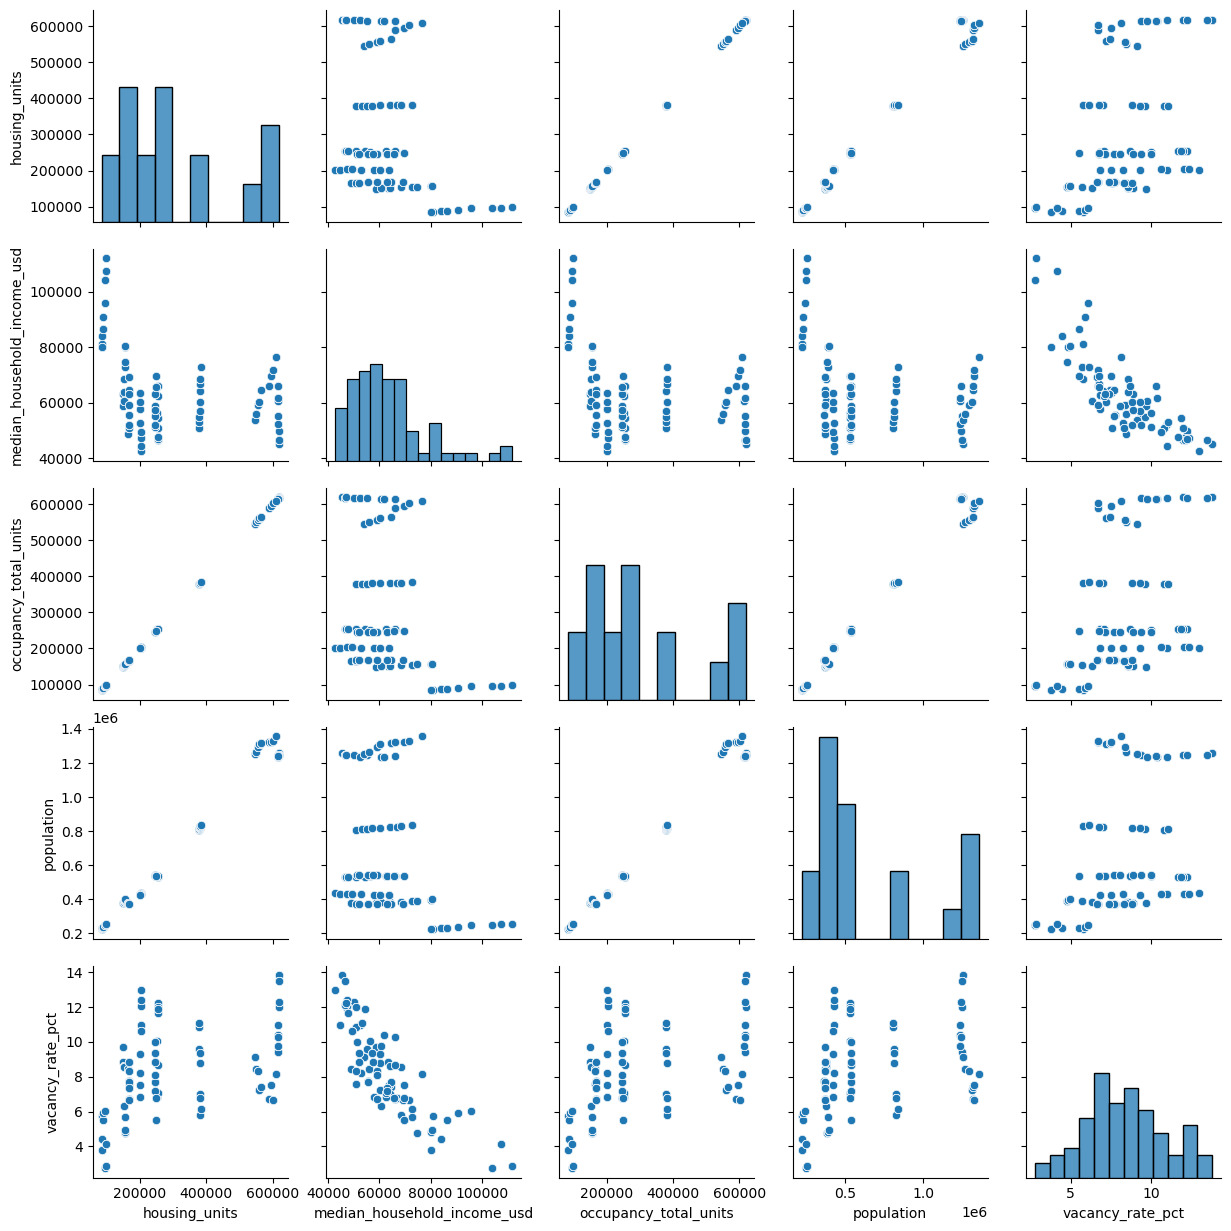

In [52]:
# labor variables pair plot
sns.pairplot(df[demo_feat[:5]])

# labor variables correlation
corr = df[demo_feat].corr()

In [53]:
for year in years:
    df_year = df[df["year"] == year]
    corr = df_year[demo_feat].corr()
    print(f"\nCorrelation Matrix for {year}")
    print(corr)


Correlation Matrix for 2015
                             housing_units  median_household_income_usd  \
housing_units                     1.000000                    -0.435123   
median_household_income_usd      -0.435123                     1.000000   
occupancy_total_units             1.000000                    -0.435123   
population                        0.994031                    -0.389850   
vacancy_rate_pct                  0.513348                    -0.843095   
vacant_housing_units              0.955870                    -0.503951   

                             occupancy_total_units  population  \
housing_units                             1.000000    0.994031   
median_household_income_usd              -0.435123   -0.389850   
occupancy_total_units                     1.000000    0.994031   
population                                0.994031    1.000000   
vacancy_rate_pct                          0.513348    0.445420   
vacant_housing_units                      0.95587

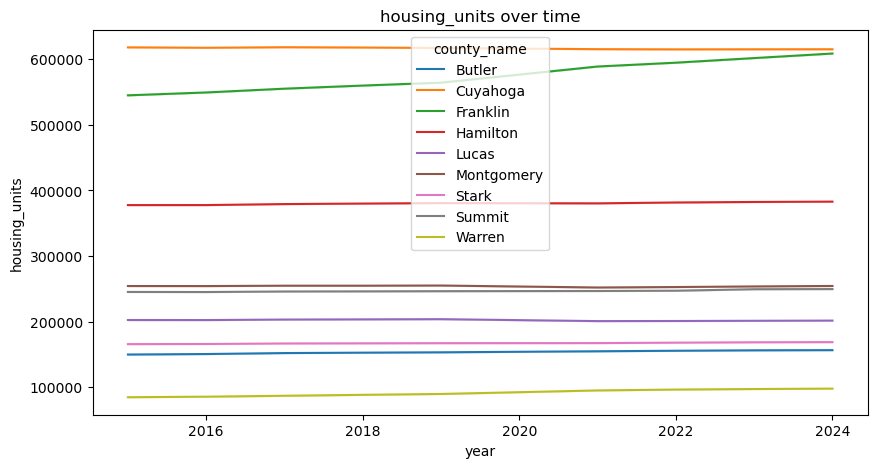

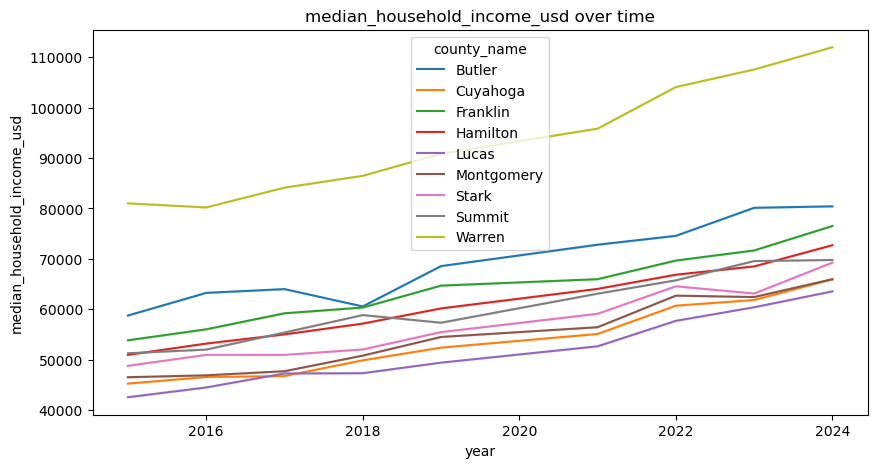

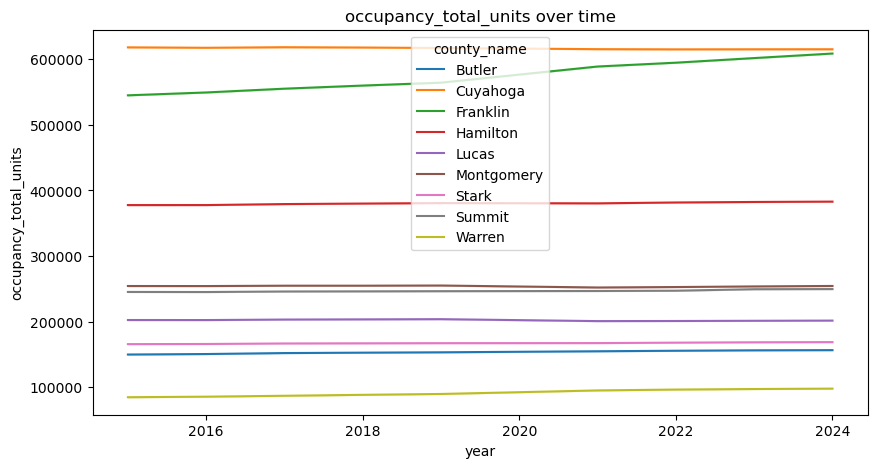

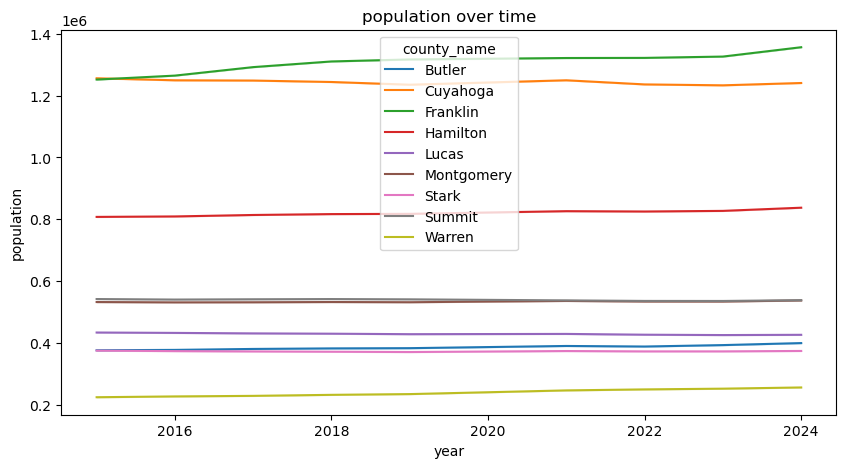

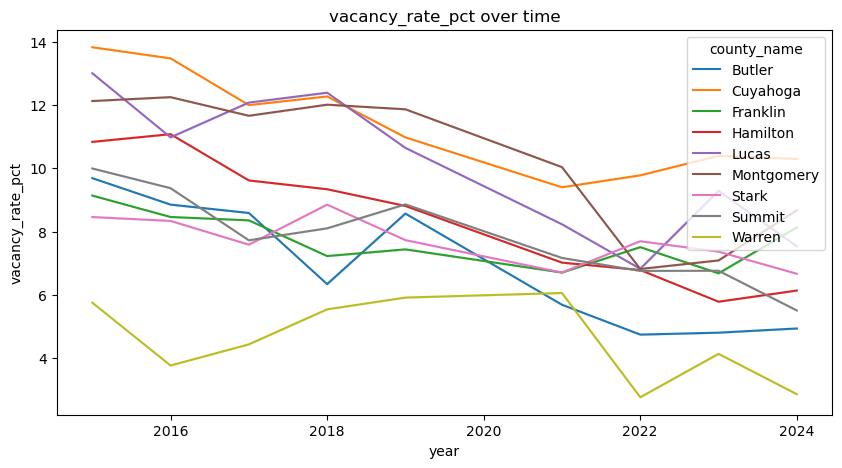

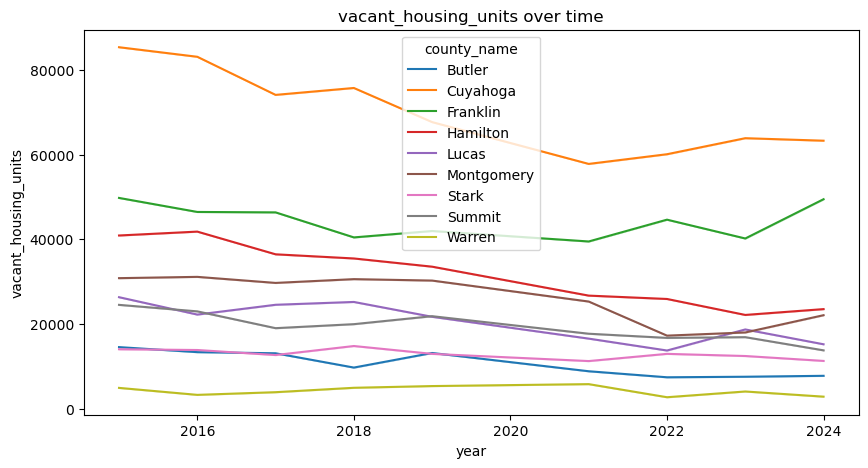

In [68]:
# One figure per labor feature
for feature in demo_feat:
    plt.figure(figsize=(10, 5))
    sns.lineplot(data=df, x="year", y=feature, hue="county_name", legend=True)
    plt.title(f"{feature} over time")
    plt.show()

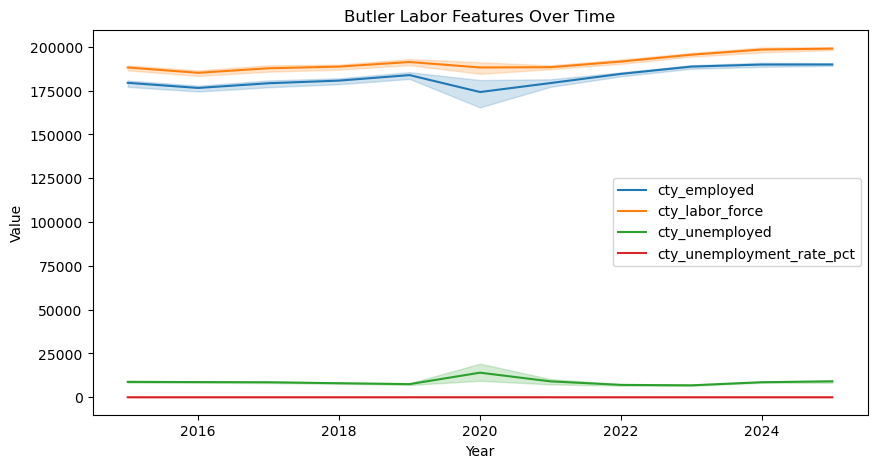

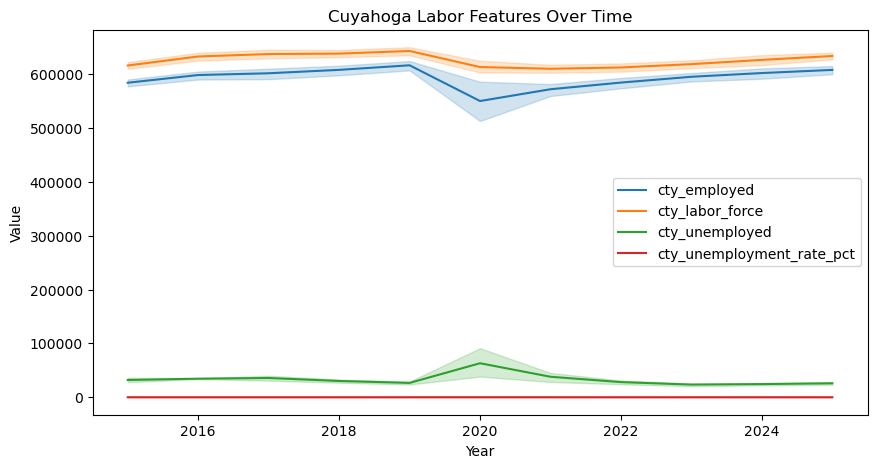

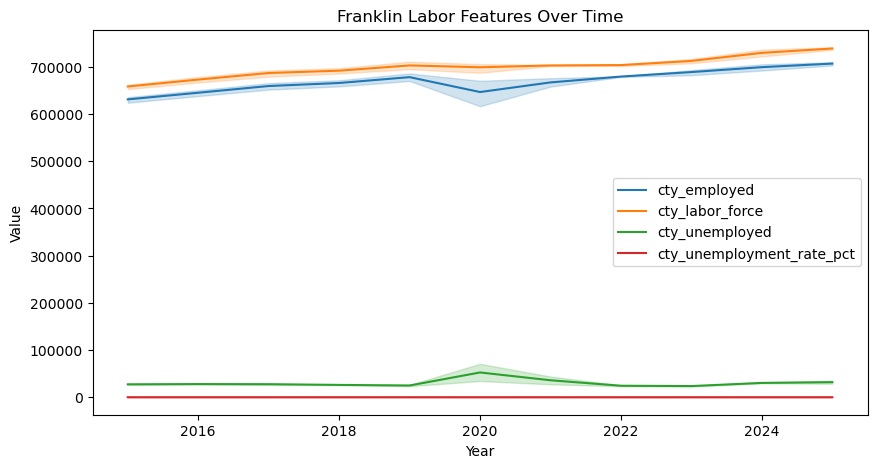

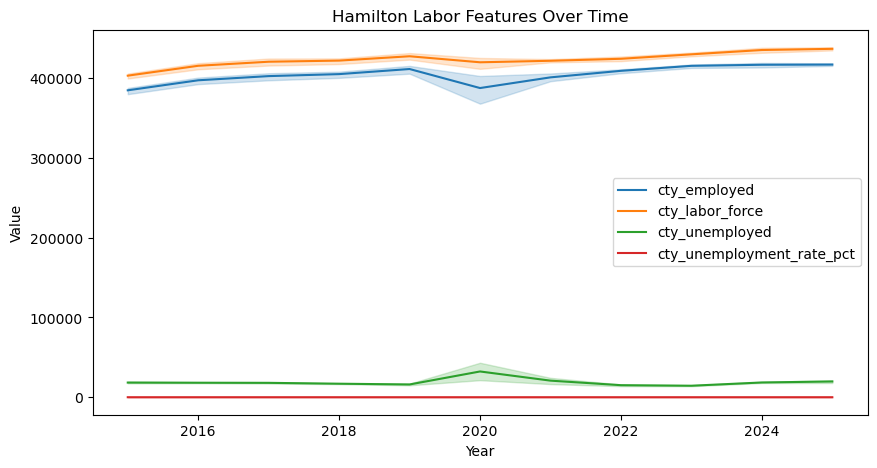

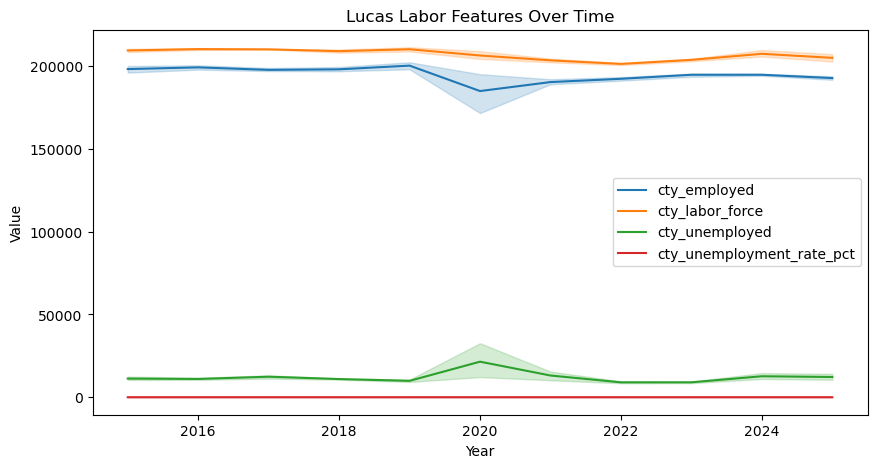

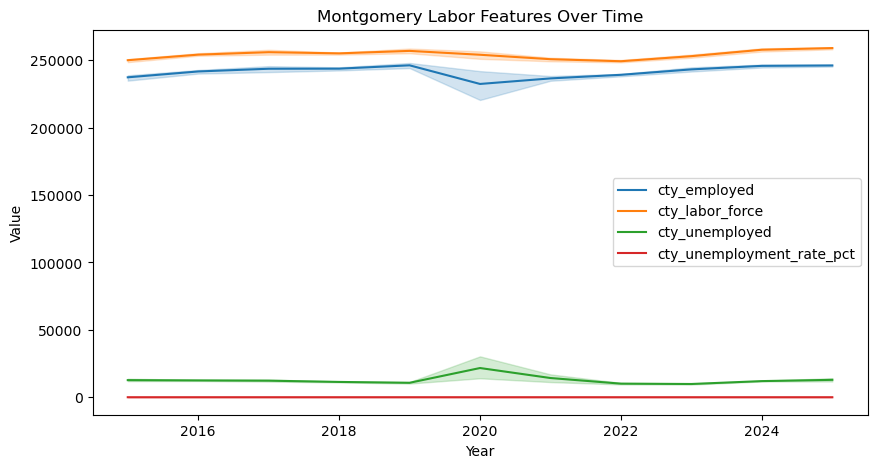

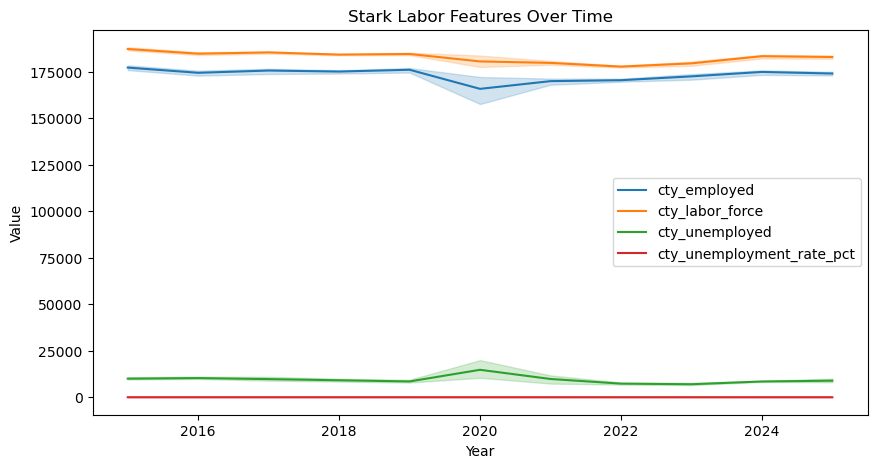

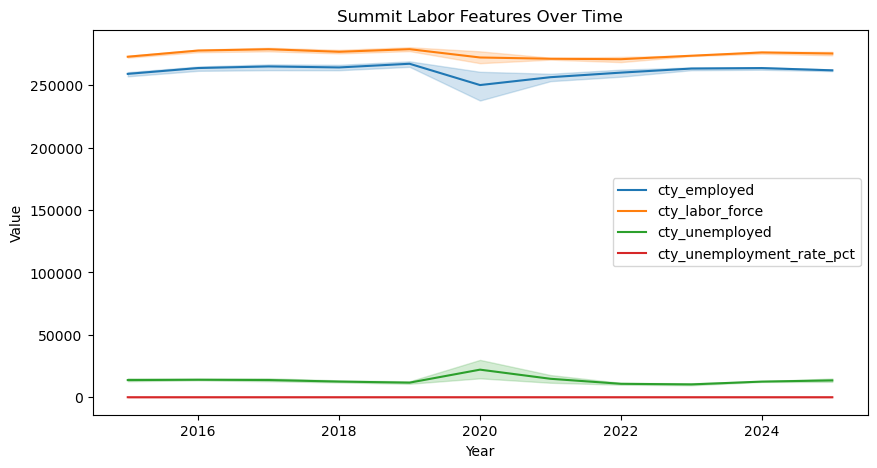

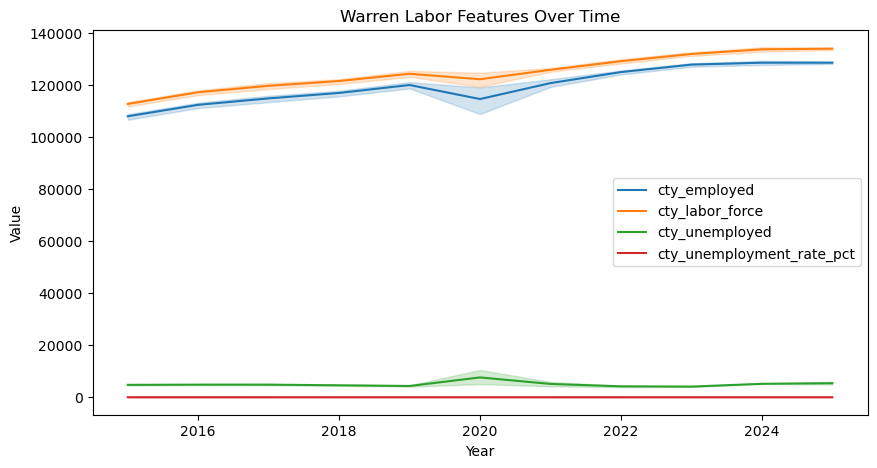

In [70]:
for county in df["county_name"].unique():
    df_county = df[df["county_name"] == county].sort_values(["year", "quarter"])

    plt.figure(figsize=(10, 5))

    for feature in labor_feat:
        sns.lineplot(data=df_county, x="year", y=feature, label=feature)

    plt.title(f"{county} Labor Features Over Time")
    plt.xlabel("Year")
    plt.ylabel("Value")
    plt.legend()
    plt.show()

# State vs. county

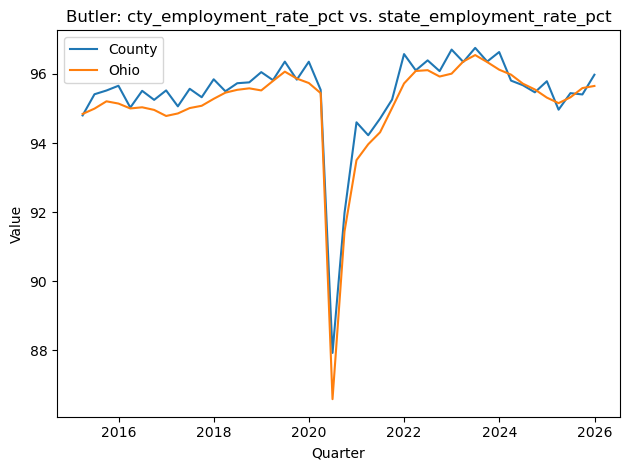

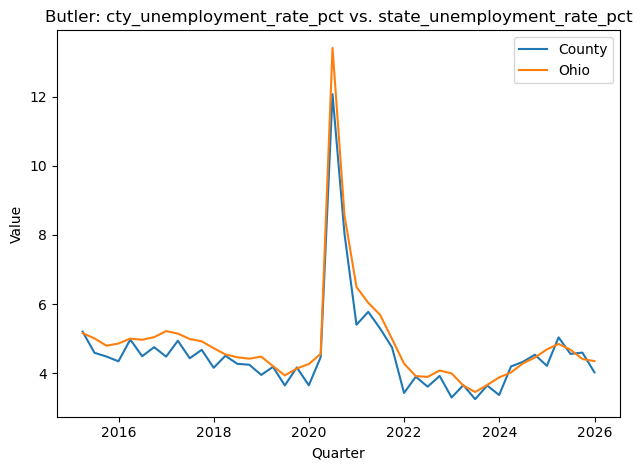

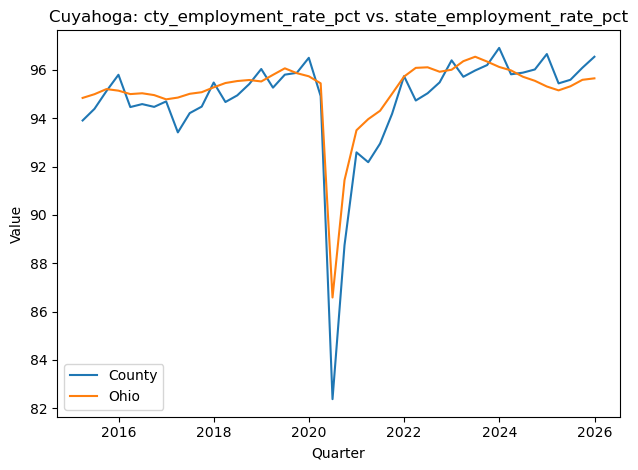

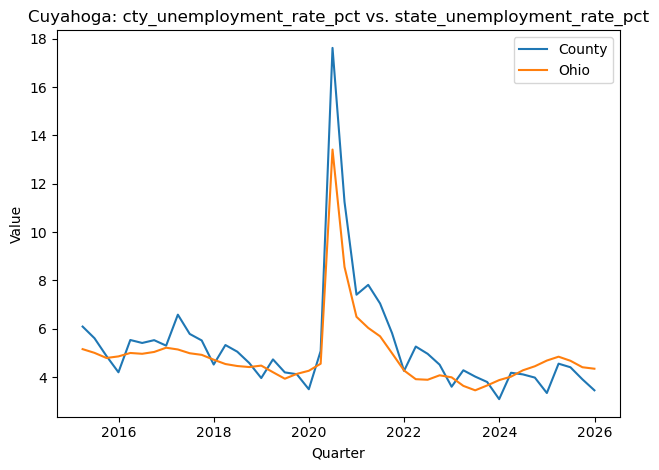

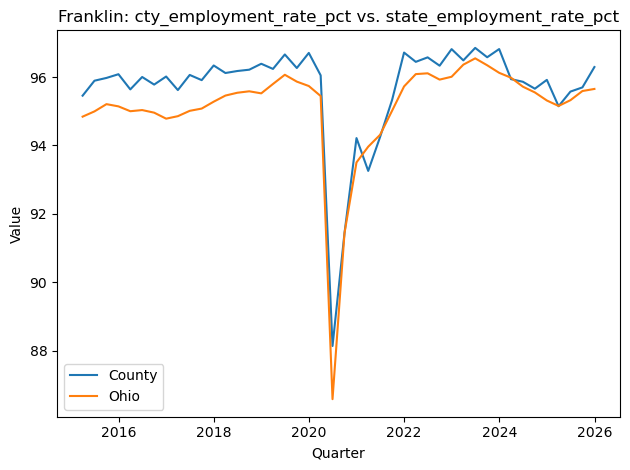

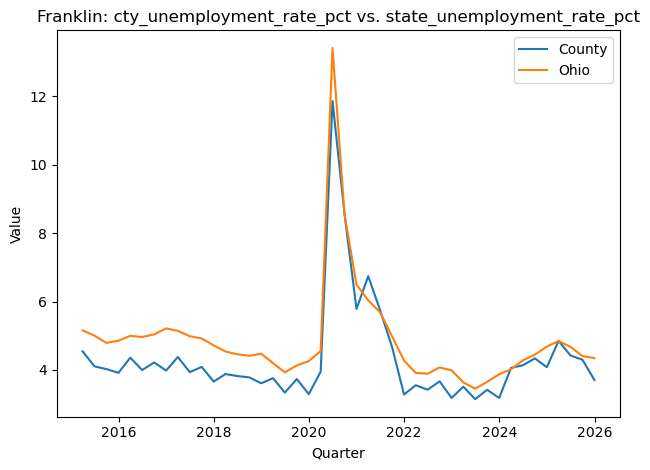

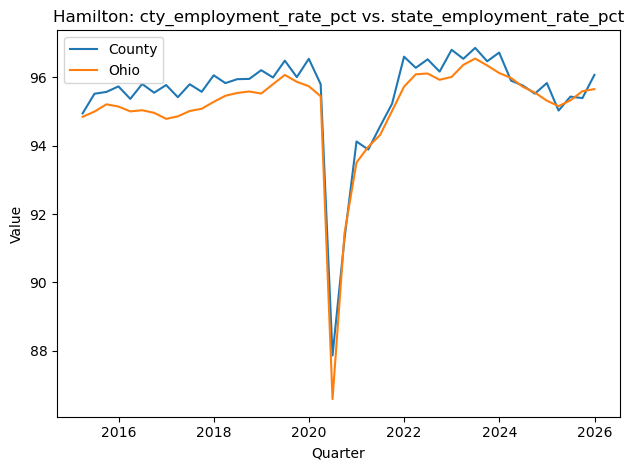

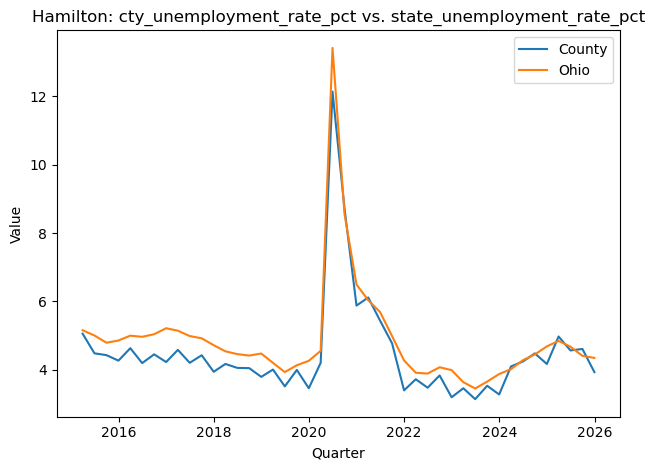

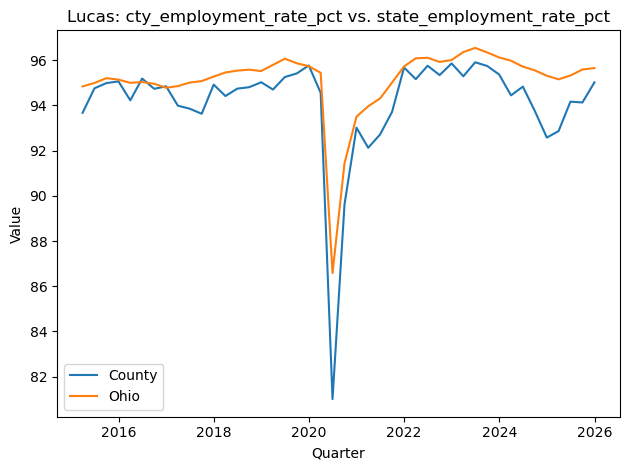

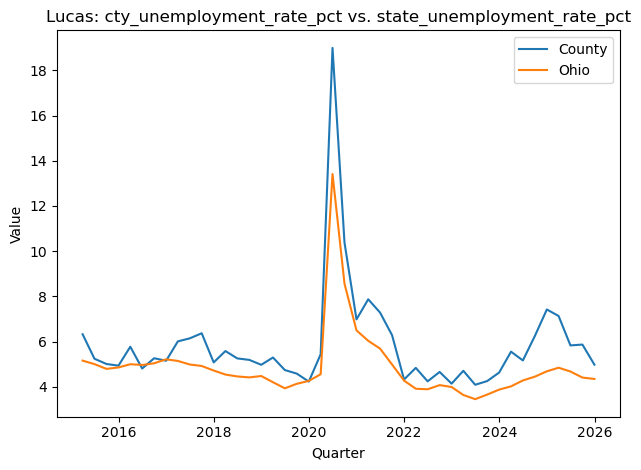

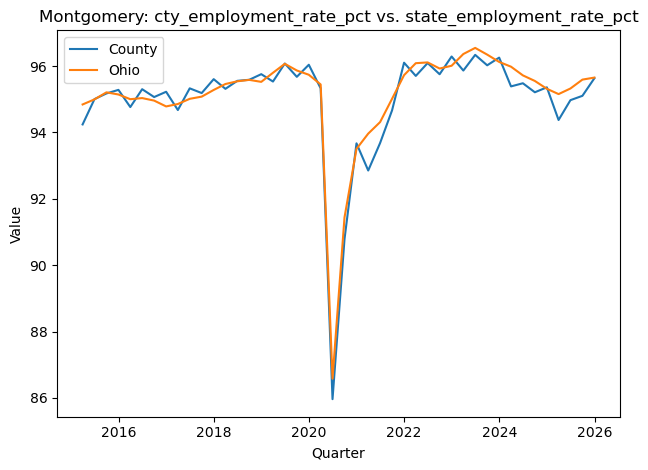

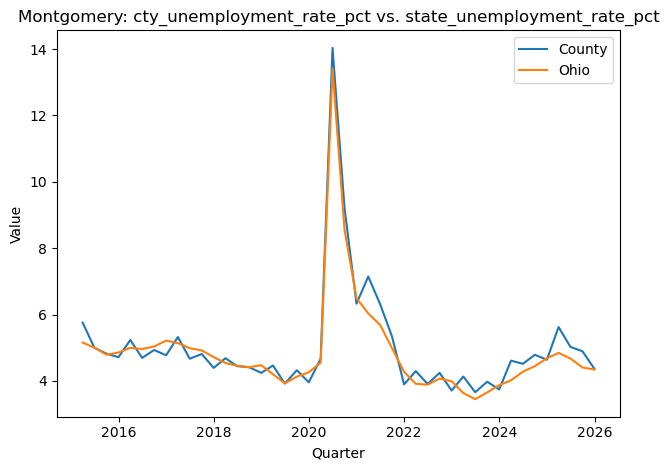

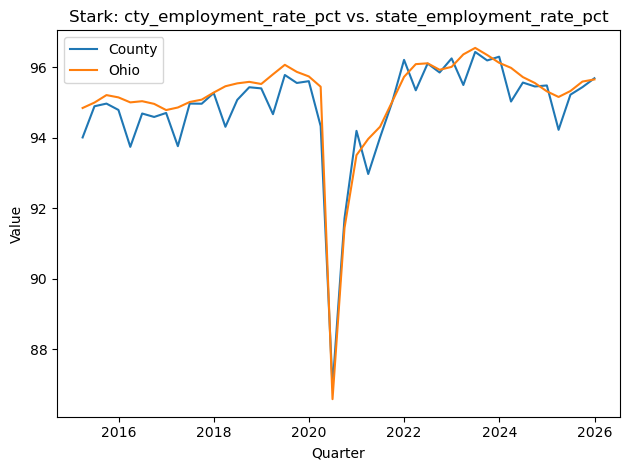

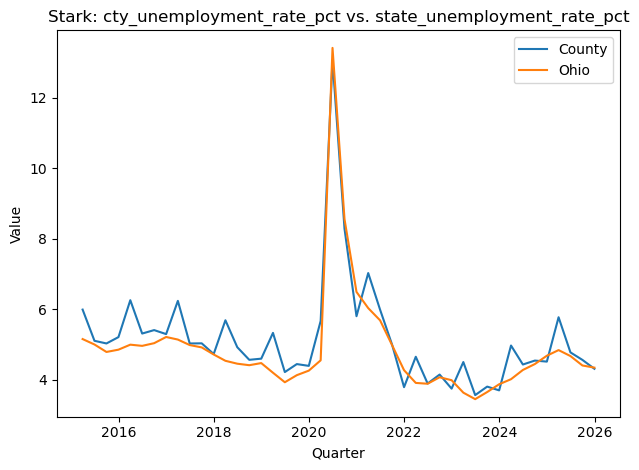

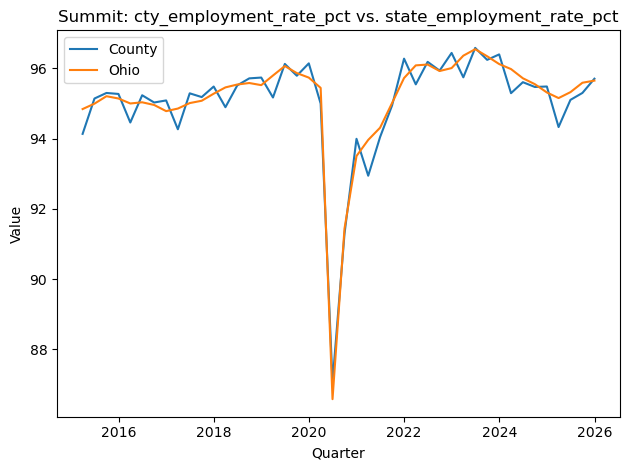

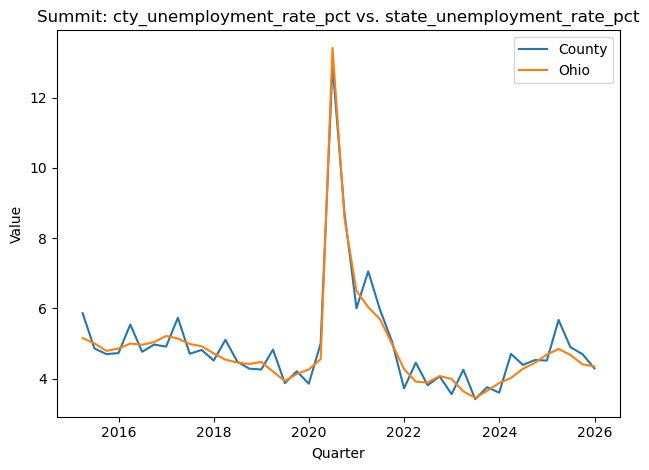

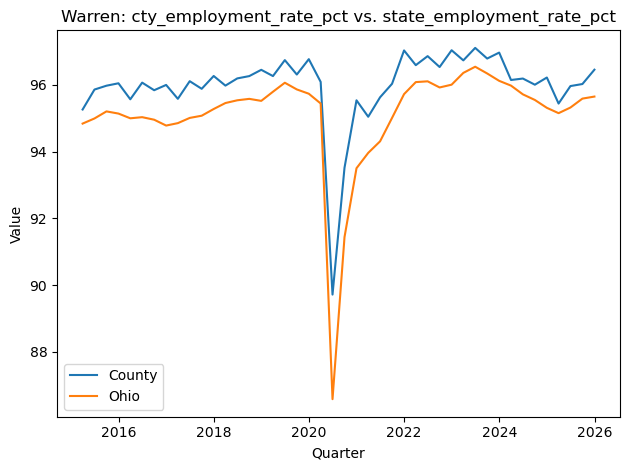

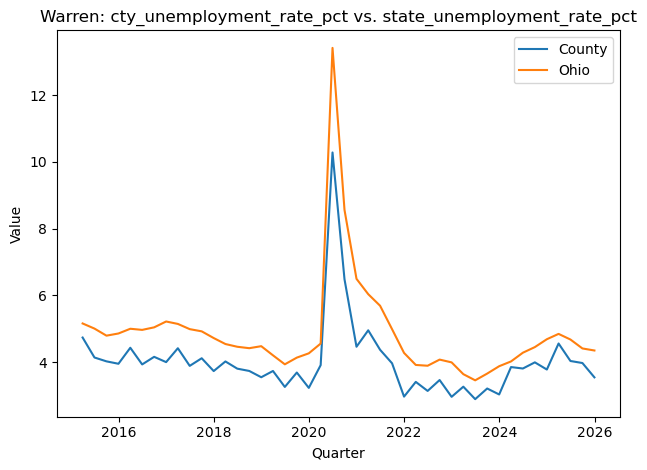

In [ ]:
df["cty_employment_rate_pct"] = (
    df["cty_employed"] / df["cty_labor_force"] * 100
)

df["state_employment_rate_pct"] = (
    df["state_employed"] / df["state_labor_force"] * 100
)

pairs = [
    ("cty_employment_rate_pct", "state_employment_rate_pct"),
    ("cty_unemployment_rate_pct", "state_unemployment_rate_pct")
]

for county in df["county_name"].unique():
    df_county = df[df["county_name"] == county].sort_values("quarter_end_date")

    for county_i, the_state in pairs:
        sns.lineplot(data=df_county, x="quarter_end_date", y=county_i,
                     label="County", errorbar=None)
        sns.lineplot(data=df_county, x="quarter_end_date", y=the_state,
                     label="Ohio", errorbar=None)

        plt.title(f"{county}: {county_i} vs. {the_state}")
        plt.xlabel("Quarter")
        plt.ylabel("Value")
        plt.legend()
        plt.tight_layout()
        plt.show()